### Visualize each point *nb_proof* in the map

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [9]:
# Set data directory
dir0 = Path('../data')
mw_filename = 'MW_instr2.nc'
mw_filepath = Path(dir0, mw_filename)
ds = xr.open_dataset(mw_filepath)

In [10]:
def global_map():
    'Generates the map of the earth'

    fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_global()  

    # Add vector background features
    ax.add_feature(cfeature.OCEAN, facecolor='#e3f2fd')
    ax.add_feature(cfeature.LAND, facecolor='#f5f5f5')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='#333333')
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, linestyle=':', edgecolor='#666666')
    return fig, ax

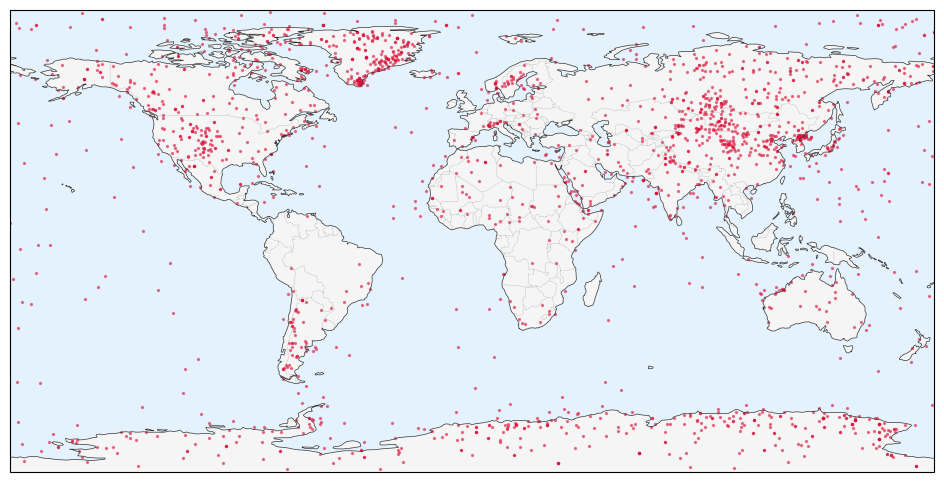

In [11]:
# Extract coordinates as numpy arrays
lons = ds["lon"].values
lats = ds["lat"].values

fig, ax = global_map()

# 2. Plot data (the view bounds will remain locked to global)
ax.scatter(
    lons, 
    lats, 
    s=2, 
    color='crimson', 
    alpha=0.5, 
    transform=ccrs.PlateCarree()
)

plt.show()

To see if the 1989 measures follow any patter, we can make a GIF plotting each at a time.

In [12]:
fig, ax = global_map()

# 2. Initialize an empty scatter plot
scat = ax.scatter([], [], s=5, color='crimson', alpha=0.7, transform=ccrs.PlateCarree())

# 3. Define the frame update function (accumulates points frame by frame)
def update(frame):
    # Slice coordinates up to the current frame index
    current_data = np.column_stack((lons[:frame + 1], lats[:frame + 1]))
    scat.set_offsets(current_data)
    return scat,

# 4. Build the animation
anim = animation.FuncAnimation(
    fig, 
    update, 
    frames=range(0, len(lons), 10), 
    interval=100,  # Milliseconds between frames
    blit=False     # Set to False for Cartopy compatibility
)

# 5. Save as GIF in imgs
anim.save('../imgs/scatter_map.gif', writer='pillow', fps=10)
plt.close()

The measurements appear to be random sampled